# Lab 05: Predict Late Deliveries

Analysis notebook. All numbers come from the files written by `python -m latedeliveries.train`. Exploration uses the **training set only**. The test set appears once, in the confusion matrix and policy costs, which are read from `reports/metrics.json`.

In [9]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from latedeliveries.evaluation import LATE_COST
from latedeliveries.pipeline import split_orders

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
X_train, X_test, y_train, y_test = split_orders()
metrics = json.loads((ROOT / "reports" / "metrics.json").read_text())
info = json.loads((ROOT / "models" / "model_info.json").read_text())

## 1. How common are late orders?

Training orders: 2250, late: 351 (15.6%)
About one order in 6.4 is late.


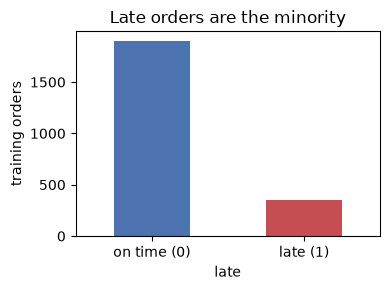

In [10]:
rate = y_train.mean()
print(f"Training orders: {len(y_train)}, late: {y_train.sum()} ({rate:.1%})")
print(f"About one order in {1 / rate:.1f} is late.")

fig, ax = plt.subplots(figsize=(4, 3))
y_train.value_counts().sort_index().plot.bar(ax=ax, color=["#4c72b0", "#c44e52"])
ax.set_xticklabels(["on time (0)", "late (1)"], rotation=0)
ax.set_ylabel("training orders")
ax.set_title("Late orders are the minority")
plt.tight_layout()
plt.show()

## 2. Model comparison (5-fold stratified CV, training data only)

`best CV cost` is the lowest out-of-fold cost over the threshold grid. Flagging nobody costs $5,265 on the training set.

In [11]:
cv = pd.read_csv(ROOT / "reports" / "cv_results.csv")
table = pd.DataFrame({"model": cv["model"]})
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    table[metric] = (
        cv[f"{metric}_mean"].map("{:.3f}".format)
        + " ± "
        + cv[f"{metric}_std"].map("{:.3f}".format)
    )
table["best threshold"] = cv["cv_best_threshold"]
table["best CV cost ($)"] = cv["cv_best_cost"]
table

,model,accuracy,precision,recall,f1,roc_auc,best threshold,best CV cost ($)
0,dummy_baseline,0.844 ± 0.001,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000,0.20,5265
1,logistic_regression,0.862 ± 0.009,0.654 ± 0.065,0.242 ± 0.053,0.352 ± 0.064,0.795 ± 0.034,0.30,4031
2,logistic_regression_balanced,0.737 ± 0.019,0.333 ± 0.027,0.681 ± 0.049,0.447 ± 0.034,0.795 ± 0.034,0.70,4098
3,random_forest,0.859 ± 0.008,0.736 ± 0.121,0.148 ± 0.036,0.246 ± 0.056,0.786 ± 0.037,0.25,4199
4,gradient_boosting,0.861 ± 0.006,0.635 ± 0.050,0.265 ± 0.024,0.373 ± 0.029,0.788 ± 0.031,0.30,4152


## 3. Cost against threshold (out-of-fold, training data)

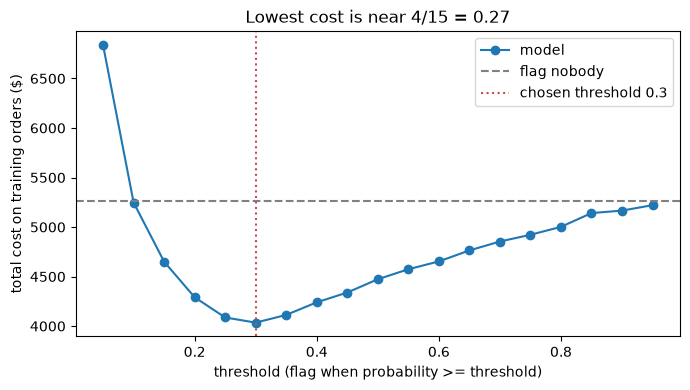

In [12]:
curve = pd.read_csv(ROOT / "reports" / "threshold_costs.csv")
best = info["threshold"]
n_late = int(y_train.sum())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(curve["threshold"], curve["cost"], marker="o", label="model")
ax.axhline(LATE_COST * n_late, color="grey", ls="--", label="flag nobody")
ax.axvline(best, color="#c44e52", ls=":", label=f"chosen threshold {best}")
ax.set_xlabel("threshold (flag when probability >= threshold)")
ax.set_ylabel("total cost on training orders ($)")
ax.set_title("Lowest cost is near $4 / $15 = 0.27")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Confusion matrix on the test set (scored once)

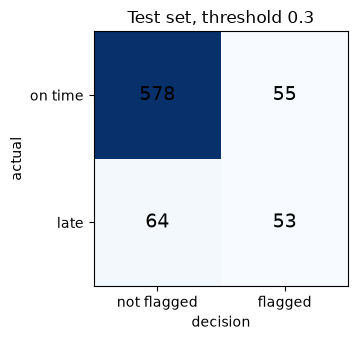

{'precision': 0.491, 'recall': 0.453, 'f1': 0.471, 'roc_auc': 0.796}


In [13]:
cm = metrics["confusion_matrix"]
grid = [
    [cm["true_negative"], cm["false_positive"]],
    [cm["false_negative"], cm["true_positive"]],
]
fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(grid, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, grid[i][j], ha="center", va="center", fontsize=14)
ax.set_xticks([0, 1], ["not flagged", "flagged"])
ax.set_yticks([0, 1], ["on time", "late"])
ax.set_xlabel("decision")
ax.set_ylabel("actual")
ax.set_title(f"Test set, threshold {metrics['threshold']}")
plt.tight_layout()
plt.show()
print({k: round(metrics[k], 3) for k in ["precision", "recall", "f1", "roc_auc"]})

## 5. Cost of the three policies on the test set

flag_nobody       1755
flag_everybody    3000
model             1392

Saving vs flagging nobody: $363 (20.7%), $0.48 per order


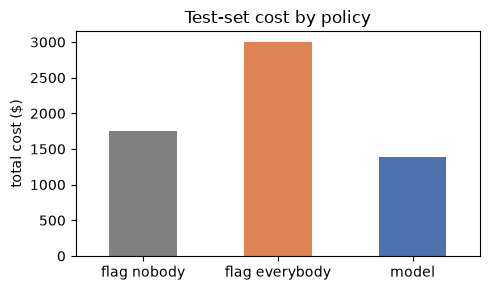

In [14]:
costs = metrics["policy_costs"]
policies = pd.Series(costs, name="total cost ($)")
print(policies.to_string())
saving = costs["flag_nobody"] - costs["model"]
print(
    f"\nSaving vs flagging nobody: ${saving} "
    f"({saving / costs['flag_nobody']:.1%}), "
    f"${saving / metrics['n_test_orders']:.2f} per order"
)

fig, ax = plt.subplots(figsize=(5, 3))
policies.plot.bar(ax=ax, color=["grey", "#dd8452", "#4c72b0"])
ax.set_xticklabels(["flag nobody", "flag everybody", "model"], rotation=0)
ax.set_ylabel("total cost ($)")
ax.set_title("Test-set cost by policy")
plt.tight_layout()
plt.show()

## 6. Seeing leakage for myself

Adding `customer_rating` (given after delivery) back in, training data only:

In [15]:
leak = json.loads((ROOT / "reports" / "leakage_check.json").read_text())
leak

{'roc_auc_without_customer_rating': 0.7950730535134147,
 'roc_auc_with_customer_rating': 0.9073141610390018,
 'difference': 0.11224110752558702}

## Recommendation

**Would I use it?** Yes, as a pilot. On 750 unseen orders it cut cost from $1,755 (flag nobody) to $1,392, about 21% or $0.48 per order. Flagging everybody costs $3,000.

**Why this threshold?** 0.30 had the lowest out-of-fold cost on training data. It sits just above the break-even probability of $4 / $15 = 0.27, because a voucher pays off whenever the chance of lateness exceeds that.

**What did I exclude?** `customer_rating` (given after delivery; adding it lifts CV ROC-AUC from 0.795 to 0.907, which is leakage) and `order_id` (a label with no meaning).

**Limitation:** the test set holds only 117 late orders, so the saving is noisy, and the data are invented. I also assume `prep_minutes` is the kitchen's estimate at order time. If it is only recorded afterwards, it must be dropped and the model retrained.